# Week 9 — Part b — K-Means Clustering

This notebook follows the unsupervised-learning section of the lecture. We will use K-Means to explore groups in a small survey-style dataset. Other unsupervised models are left to you to explore and learn in your free time (they won't be a part of our exam but they are also important aspects of machine learning).

### Learning objectives

By the end, you should be able to:

- distinguish supervised from unsupervised learning;
- explain clustering, distance and centroids;
- run K-Means and describe its iterative process;
- explain why feature scaling matters;
- use the elbow method and silhouette score as guides for choosing $K$;
- describe clusters and recognise important limitations of K-Means.

The synthetic dataset is in `../data/week9_sleep_stress.csv`.


## 1. From prediction to discovery

So far, most of our examples have been **supervised learning**: the data include a target or label, and the model learns to predict it.

In **unsupervised learning**, there is no target label supplied to the algorithm. We instead look for structure in the observations.

**Clustering** groups observations according to similarity:

- observations in the same cluster should be relatively similar;
- observations in different clusters should be relatively dissimilar;
- the groups are not supplied in advance.

K-Means is one clustering algorithm. It uses distance to assign observations to clusters.

## 2. Load the survey-style fake dataset

The dataset has two features, as in the lecture's example:

- average daily sleep (hours);
- self-reported stress (scale from 1 to 10).

The observations are **synthetic**: they were created for teaching and are not real survey responses.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

observations = pd.read_csv("../data/week9_sleep_stress.csv")

print(f"Number of observations: {len(observations)}")
observations.head()

Number of observations: 300


,sleep_hours,stress_score
0,6.8,5
1,6.8,6
2,6.5,7
3,7.5,1
4,6.0,6


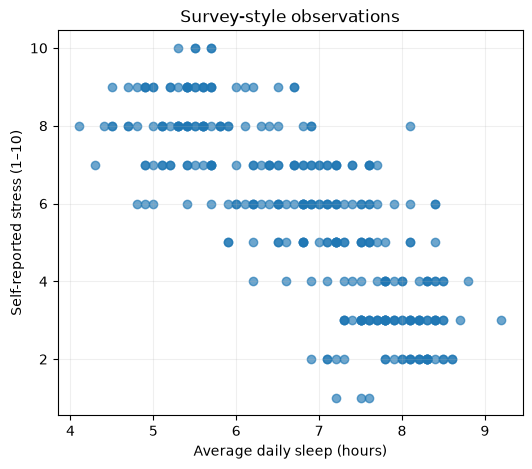

In [2]:
plt.figure(figsize=(6, 5))
plt.scatter(
    observations["sleep_hours"],
    observations["stress_score"],
    alpha=0.65
)
plt.xlabel("Average daily sleep (hours)")
plt.ylabel("Self-reported stress (1–10)")
plt.title("Survey-style observations")
plt.grid(alpha=0.2)
plt.show()

Before clustering, look at the scatter plot. Do you see possible groups? Could the points instead represent a continuous range of sleep and stress profiles?

Remember: a visual impression is not proof that objectively real groups exist. And in this particular case they don't.

## 3. Distance and feature scaling

A common distance measure is **Euclidean distance**. For two observations with two features,

$$
d(\mathbf{x}, \mathbf{y}) = \sqrt{(x_1-y_1)^2 + (x_2-y_2)^2}
$$

Distance is affected by the scale of the features as we observed also in KNN for finding the K nearest neighbors. A feature measured in thousands can dominate a feature measured in single digits. Standardisation as a way of scaling puts features on a comparable scale by subtracting the mean and dividing by the standard deviation.

Even when features have similar-looking ranges, it is important to consider their units, ranges and substantive meaning before using a distance-based method.

In [3]:
from sklearn.preprocessing import StandardScaler

features = ["sleep_hours", "stress_score"]

print("Original feature ranges:")
display(observations[features].agg(["min", "max", "mean", "std"]).round(2))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(observations[features])

scaled_data = pd.DataFrame(X_scaled, columns=features)
print("Standardised feature ranges:")
display(scaled_data.agg(["min", "max", "mean", "std"]).round(2))

Original feature ranges:


,sleep_hours,stress_score
min,4.10,1.00
max,9.20,10.00
mean,6.80,5.66
std,1.15,2.30


Standardised feature ranges:


,sleep_hours,stress_score
min,-2.35,-2.03
max,2.08,1.89
mean,0.00,-0.00
std,1.00,1.00


## 4. How K-Means works

K-Means aims to divide the observations into $K$ clusters so that each observation is close to the **centroid** of its assigned cluster. A centroid is the mean position of the observations in that cluster.

The algorithm repeats these steps:

1. Choose the number of clusters, $K$.
2. Place $K$ initial centroids (There are different initialisation method like a random initialisation or K-Means++. K-Means++ as opposed to purely random centroids, picks starting centroids that are far apart, which makes a poor result less likely.).
3. Assign each observation to its nearest centroid.
4. Move each centroid to the mean of its assigned observations.
5. Repeat the assignment and update steps until the assignments or centroids stop changing (or the stopping criterion is reached).

Different initial centroids can lead to different solutions. We will use `n_init=20`, which runs the algorithm from multiple initialisations and keeps the best result according to the K-Means objective.

In [4]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=20,
    random_state=42
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Centroids are returned in standardised coordinates.
centres_scaled = kmeans.cluster_centers_
#Reminder:
# The trailing underscore is a scikit-learn convention: it marks attributes
# learned from the data during .fit() (e.g. cluster_centers_, labels_, inertia_),
# as opposed to settings we choose ourselves (e.g. n_clusters).

# Convert centroids back to the original feature units for interpretation.
centres_original = scaler.inverse_transform(centres_scaled)

print(f"Inertia: {kmeans.inertia_:.2f}")
print("Number of observations in each cluster:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Inertia: 101.97
Number of observations in each cluster:
0    100
1     94
2    106
Name: count, dtype: int64


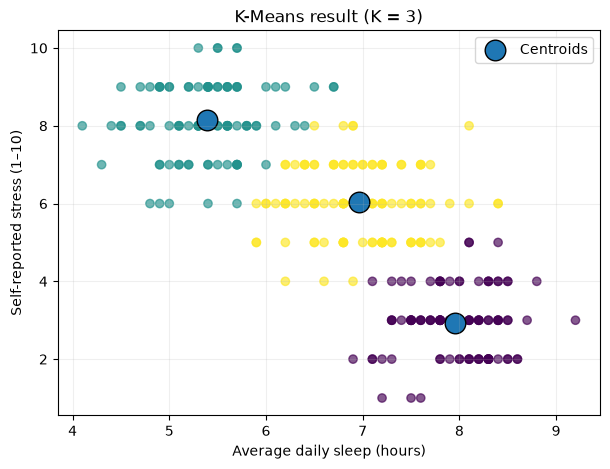

In [5]:
clustered_data = observations.copy()
clustered_data["cluster"] = cluster_labels

plt.figure(figsize=(7, 5))
plt.scatter(
    clustered_data["sleep_hours"],
    clustered_data["stress_score"],
    c=clustered_data["cluster"],
    alpha=0.65
)
plt.scatter(
    centres_original[:, 0],
    centres_original[:, 1],
    marker="o",
    s=220,
    edgecolor="black",
    label="Centroids"
)
plt.xlabel("Average daily sleep (hours)")
plt.ylabel("Self-reported stress (1–10)")
plt.title("K-Means result (K = 3)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Interpret the plot**

- What does each coloured group represent in terms of the two features?
- What does a centroid represent?
- Are the cluster boundaries sharp, or do some observations lie close to another cluster?

The numerical cluster IDs (0, 1, 2) are arbitrary labels. Cluster 2 is not inherently “better” or more important than cluster 0.

## 5. Describe the clusters

Finding clusters is only the beginning. We need to inspect their characteristics and decide whether the differences are meaningful for the research question.

The table below shows the mean sleep and stress values within each cluster. It is often useful to inspect distributions as well, because averages can hide variation within a cluster.

In [6]:
cluster_summary = (
    clustered_data
    .groupby("cluster")[features]
    .agg(["count", "mean", "std"])
    .round(2)
)

cluster_summary

sleep_hours             stress_score            
              count  mean   std        count  mean   std
cluster                                                 
0               100  7.96  0.44          100  2.94  0.85
1                94  5.39  0.50           94  8.14  0.96
2               106  6.96  0.55          106  6.03  0.92

**Questions for interpretation**

1. Which cluster has the highest average stress score?
2. Which cluster has the highest average sleep duration?
3. Are the groups meaningfully distinct for a plausible research question?
4. Could the apparent groups be an artefact of the features selected or the algorithm?

Do not assign labels such as “healthy”, “unhealthy” or “high risk” unless those interpretations are justified by the research design and evidence.


Important note:
Visualisation was a great asset when we have a few (here a single) feature but as the number of features grow, we have less and less of an intuition coming from plotting the data in 2-3D.

## 6. How do we choose K?

K-Means requires us to choose $K$ in advance. Two common guides are:

### Elbow method

- Fit K-Means for several values of $K$.
- Plot **inertia** (the within-cluster sum of squared distances to the assigned centroid).
- Look for a point where the improvement starts to level off.
- Inertia always decreases as $K$ increases, so an elbow is not guaranteed to be clear.

### Silhouette score

For each observation, the silhouette score compares how close it is to its own cluster with how close it is to the nearest other cluster.

- The score ranges from -1 to 1.
- A higher average score generally indicates better separation between clusters.
- It is a guide, not an automatic answer.

Domain knowledge, interpretability and the research question still matter.

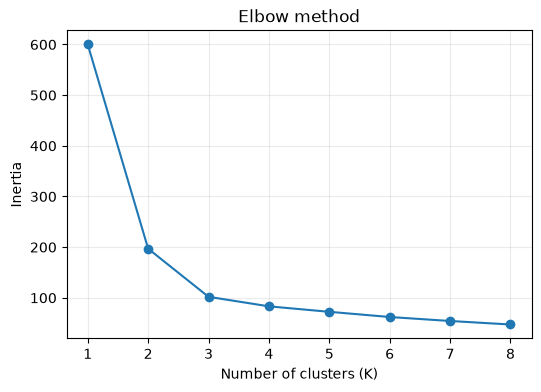

In [7]:
from sklearn.metrics import silhouette_score

k_values = range(1, 9)
inertias = []

for k in k_values:
    candidate = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )
    candidate.fit(X_scaled)
    inertias.append(candidate.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.grid(alpha=0.25)
plt.show()

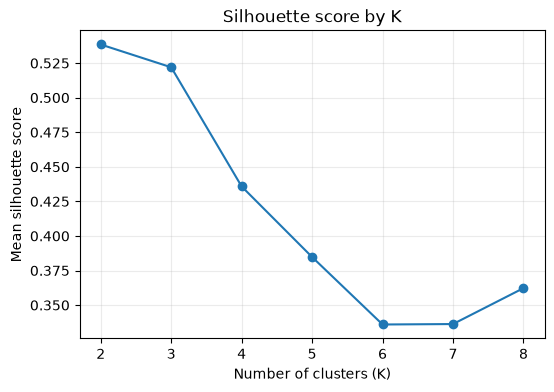

,K,mean_silhouette
0,2,0.538
1,3,0.522
2,4,0.436
3,5,0.385
4,6,0.336
5,7,0.336
6,8,0.362


In [8]:
silhouette_scores = []
silhouette_k_values = range(2, 9)

for k in silhouette_k_values:
    candidate = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )
    labels = candidate.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(6, 4))
plt.plot(list(silhouette_k_values), silhouette_scores, marker="o")
plt.xticks(list(silhouette_k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Mean silhouette score")
plt.title("Silhouette score by K")
plt.grid(alpha=0.25)
plt.show()

pd.DataFrame({
    "K": list(silhouette_k_values),
    "mean_silhouette": silhouette_scores
}).round(3)

**Compare the two guides**

- Which value of $K$ has the highest silhouette score in this example?
- Where, if anywhere, does the inertia plot show an elbow?
- Do the two methods point to the same value of $K$?
- Would you choose $K$ based only on these metrics?

The scores are diagnostics, not proof that natural groups exist in the data.

## 7. Limitations and good practice

Keep the lecture's limitations in mind:

- Results depend on which features are selected and how they are scaled.
- Different distance measures can lead to different groupings.
- K-Means works best with roughly round, similarly sized clusters; it can struggle with elongated or curved groups.
- It always returns the requested number of clusters, even if the data have no meaningful group structure.
- In high-dimensional data, distances can become less informative.
- Cluster assignments can depend on initialisation; use multiple initialisations and check stability.

A cluster is a mathematical result, not automatically a scientific discovery. Researchers must interpret and validate clusters.